In [1]:
import pandas as pd
import numpy as np
from pprint import pprint
import time
import os
import matplotlib.pyplot as plt
from typing import *
import math

plt.rcParams["figure.figsize"] = (20,3)

In [2]:
#* Constants
startingDate = "2020-01-01"
endingDate = "2023-12-31"

#* Format des données horraires
startingDateInt = "2020010100"
endingDateInt = "2023123123"
regions_departements = {
    "Auvergne-Rhône-Alpes": [
        1, 3, 7, 15, 26, 38, 42, 43, 63, 69, 73, 74
    ],
    "Bourgogne-Franche-Comté": [
        21, 25, 39, 58, 70, 71, 89, 90
    ],
    "Bretagne": [
        22, 29, 35, 56
    ],
    "Centre-Val de Loire": [
        18, 28, 36, 37, 41, 45
    ],
    "Corse": [
        20
    ],
    "Grand Est": [
        8, 10, 51, 52, 54, 55, 57, 67, 68, 88
    ],
    "Hauts-de-France": [
        2, 59, 60, 62, 80
    ],
    "Ile-de-France": [
        75, 77, 78, 91, 92, 93, 94, 95
    ],
    "Nouvelle-Aquitaine": [
        16, 17, 19, 23, 24, 33, 40, 47, 64, 79, 86, 87
    ],
    "Normandie": [
        14, 27, 50, 61, 76
    ],
    "Occitanie": [
        9, 11, 12, 30, 31, 32, 34, 46, 48, 65, 66, 81, 82
    ],
    "Pays de la Loire": [
        44, 49, 53, 72, 85
    ],
    "Provence-Alpes-Côte d'Azur": [
        4, 5, 6, 13, 83, 84
    ]
}


In [3]:
def getFileName(step:Literal["raw","cleaned"],dataSource:Literal["meteo","energy"],delta:Literal["ByDay","ByHour"]=None,departementNumber:int=None,region:str=None,year:int=None):
    MetoBase = "DEP-"
    if dataSource=="energy":
        if step=="raw":
            # print(os.path.join(step+"Data",dataSource,f"eCO2mix_RTE_{region}_Annuel-Definitif_{year}.zip"))
            return os.path.join(step+"Data",dataSource,f"eCO2mix_RTE_{region}_Annuel-Definitif_{year}.csv")
        else:
            return os.path.join(step+"Data",dataSource,f"Consommation_{region}.csv")
    if dataSource=="meteo":
        if step=="raw":
            number = str(departementNumber) if departementNumber>10 else "0"+str(departementNumber)
            return os.path.join(step+"Data",dataSource,delta,MetoBase+number+".csv")
        else:
            number = str(departementNumber) if departementNumber>10 else "0"+str(departementNumber)
            return os.path.join(step+"Data",dataSource,delta,MetoBase+number+".csv")
        
    number = str(departementNumber) if departementNumber>10 else "0"+str(departementNumber)
    return os.path.join(step+"Data",dataSource,MetoBase+number+".csv")

avt drop na (1461, 9)
apr drop na (1461, 9)
Index(['TN', 'TX', 'TM', 'TNSOL', 'TN50', 'DG', 'FF2M', 'DRR', 'Date'], dtype='object')


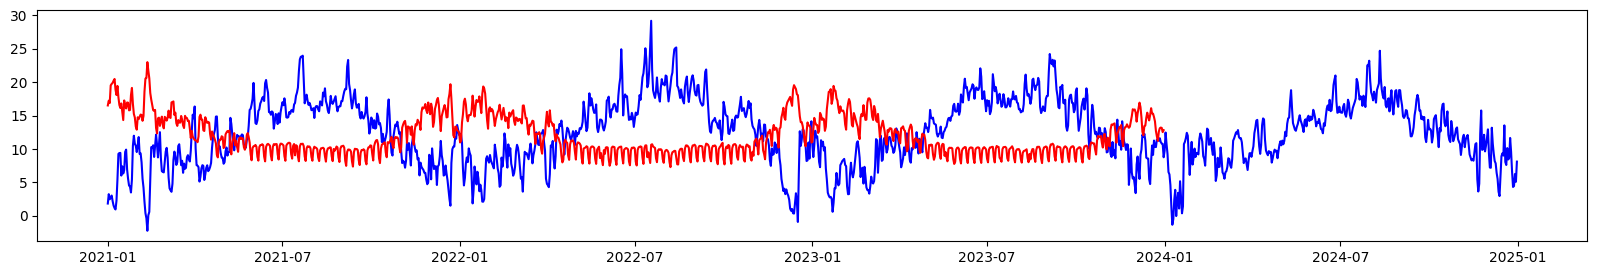

In [5]:
#* Check if there exist a correlation

regionTested = "Bretagne"

energyData = pd.read_csv(getFileName("cleaned",'energy',region=regionTested))
# print(energyData)
energyData["Consommation"] = energyData["Consommation"] / 10_000
energyData["Date"] = pd.to_datetime(energyData["Date"],format="%m/%d/%Y")
energyData = energyData.sort_values("Date")
# energyData = energyData.set_index("Date")
departementsData = [pd.read_csv(getFileName("cleaned","meteo",delta="ByDay",departementNumber=dep),index_col=0) for dep in regions_departements[regionTested]]
# print(departementsData[0].head())
departementUnited = pd.concat(departementsData)
# departementUnited
regionAverage = departementUnited.groupby(["AAAAMMJJ"]).mean()
regionAverage["Date"] = pd.to_datetime(regionAverage.index)
print("avt drop na",regionAverage.shape)
regionAverage = regionAverage.dropna(subset=["TM"])
print("apr drop na",regionAverage.shape)

# regionAverage = regionAverage[regionAverage.index <= energyData.index[-1]]
print(regionAverage.columns)

plt.plot(regionAverage['Date'],regionAverage["TM"],color="blue")
plt.plot(energyData['Date'],energyData["Consommation"],color="red")
plt.show()

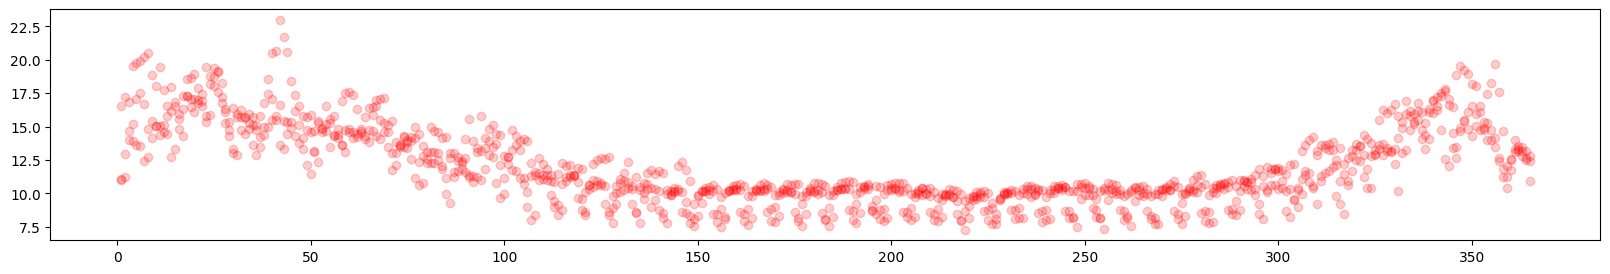

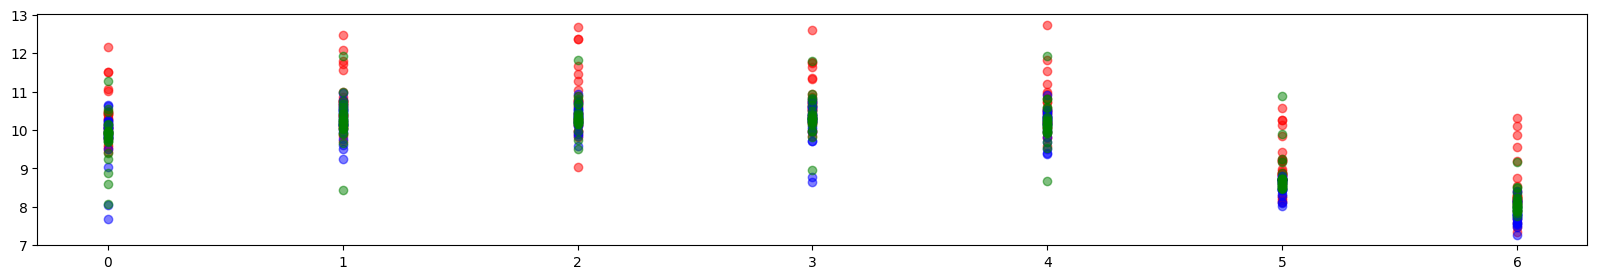

In [29]:
energyZoom21 = energyData[(energyData["Date"]>="2021-05-01") & (energyData["Date"]<="2021-10-28")]
energyZoom22 = energyData[(energyData["Date"]>="2022-05-01") & (energyData["Date"]<="2022-10-28")]
energyZoom23 = energyData[(energyData["Date"]>="2023-05-01") & (energyData["Date"]<="2023-10-28")]

# plt.plot(meteoZoom['Date'],meteoZoom["TM"],color="blue")
plt.scatter(energyData['Date'].dt.dayofyear,energyData["Consommation"],color="red",alpha=0.2)
plt.show()

plt.scatter(energyZoom21['Date'].dt.dayofweek,energyZoom21["Consommation"],color="red",alpha=0.5)
plt.scatter(energyZoom22['Date'].dt.dayofweek,energyZoom22["Consommation"],color="blue",alpha=0.5)
plt.scatter(energyZoom23['Date'].dt.dayofweek,energyZoom23["Consommation"],color="green",alpha=0.5)
plt.show()


En été les jours de la semaine sont très importants pour la consommation d'énergie

In [4]:
#* Premier essai ML 
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.model_selection import GridSearchCV

# from sklearn.preprocessing import columnsTransforme

In [31]:
combineData = energyData.merge(regionAverage,"inner",left_on="Date",right_on="Date")

print(combineData.shape)
combineData = combineData.dropna()
print(combineData.shape)

(1095, 10)
(1094, 10)


score :  0.8244160832250796


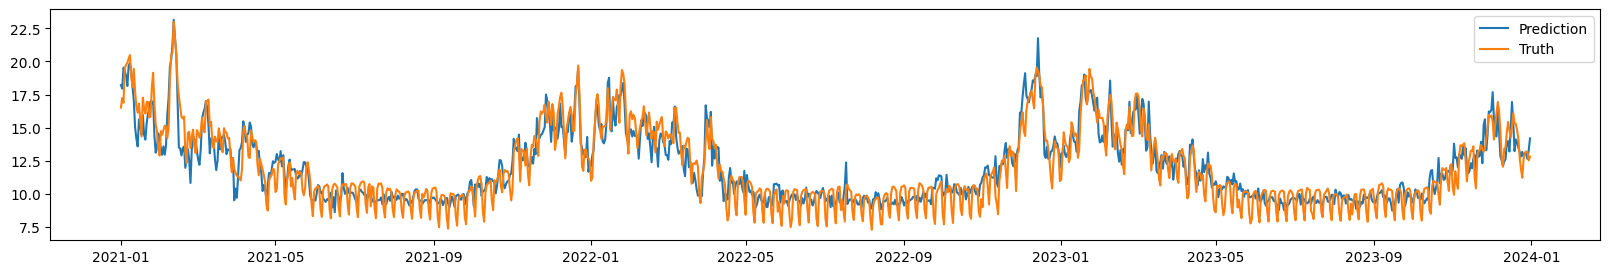

In [32]:
#* Ensure that we have the same data for each day : 

degree = 2
poly = PolynomialFeatures(degree)

linReg = LinearRegression()

linRegPipe = Pipeline([('poly',poly),("linReg",linReg)])
# features = combineData.drop(["Date","Consommation"],axis=1).to_numpy()
features = combineData[['TN', 'TX', 'TM', 'TNSOL', 'TN50', 'DG', 'FF2M', 'DRR']].to_numpy()
# features = combineData[['TM']].to_numpy()
y = combineData[["Consommation"]].to_numpy()

# X = poly.fit_transform(features)
Xtrain,Xtest, yTrain, yTest = train_test_split(features,y,test_size=0.2)

linRegPipe.fit(Xtrain,yTrain)

# XtrainPoly = poly.fit_transform(Xtrain)
# XtestPoly = poly.fit_transform(Xtest)
# linRegScores = cross_val_score(linRegPipe,Xtrain,yTrain,cv=400)
# linRegPipe.fit(Xtrain,yTrain)
# linRegPipe.score(Xtest,yTest)
# linReg.fit(Xtrain,yTrain)
# linReg.score(Xtest,yTest)
# print(f"mean : {linRegScores.mean()}, var : {linRegScores.var()}")


# print(f'The regression coef {linReg.coef_}')
# print(f'The R^2 determination coef {linReg.score(Xtest,yTest)}')    
# print(f'The RSS {mean_squared_error(yTest,linReg.predict(Xtest))}')    

# linReg.score(XtrainPoly,yTrain)
# X.shape, y.shape
# regionAverage.tail(), energyData.tail()
# combineData
print("score : ",linRegPipe.score(Xtest,yTest))
plt.plot(combineData["Date"],linRegPipe.predict(features),label="Prediction")
plt.plot(combineData["Date"],y,label="Truth")
plt.legend()
plt.show()

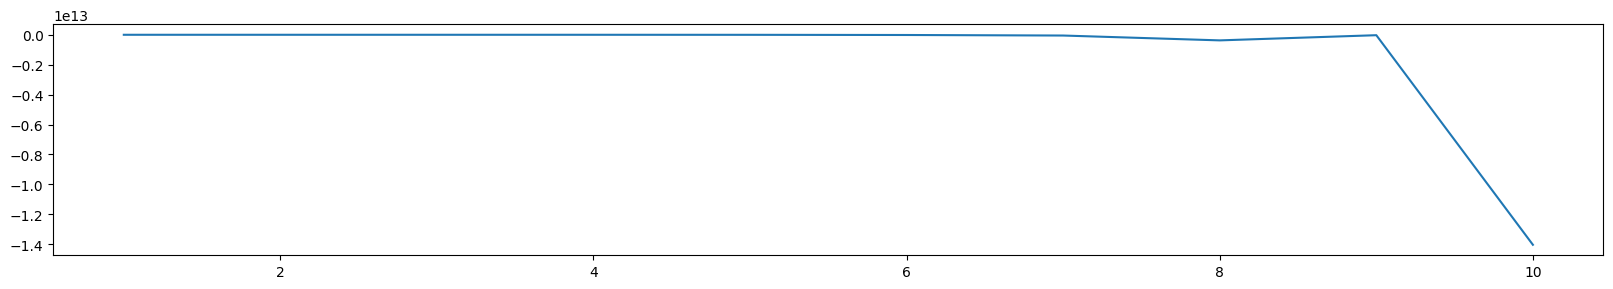

Score : 0.8244


In [34]:
n_splits = 10
kmax = 10

param_grid = {"poly__degree": list(range(1, kmax + 1))}
grid_search = GridSearchCV(estimator = linRegPipe, param_grid = param_grid, cv = n_splits, n_jobs=-1)

grid_search.fit(Xtrain, yTrain)

# k_best = grid_search.best_estimator_.named_steps["poly"]

searchResults =  pd.DataFrame(grid_search.cv_results_)

plt.plot(searchResults["param_poly__degree"],searchResults["mean_test_score"])
plt.show()

print(f"Score : {grid_search.best_estimator_.score(Xtest, yTest):.4f}")


In [ ]:
XSimple = combineData[["TM","FF2M","DRR"]].to_numpy()

Xtrain2,Xtest2,yTrain2,yTest2 = train_test_split(XSimple,y)

linReg.fit(Xtrain2,yTrain2)
linReg.score(Xtest2,yTest2)


0.6739529101350679

[0.76726548]


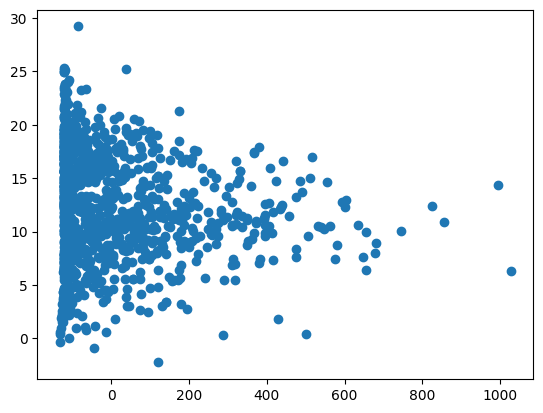

In [ ]:
#* Trying reduce dimension with PCA

d = 2

pca = PCA(d)

# pca.fit(features)
# pca.explained_variance_


pcaLinRegPipe = Pipeline([("pca",pca)]+linRegPipe.steps)
pcaLinRegPipe.fit(Xtrain,yTrain)
pcaLinRegPipe.score(Xtest,yTest)
# pcaLinRegScores = cross_val_score(pcaLinRegPipe,Xtrain,yTrain,cv=400)
# print(f"mean : {pcaLinRegScores.mean()}, var : {pcaLinRegScores.var()}")
# print(f"coef : {pcaLinRegPipe["linReg"].coef_}")

XPca = pca.fit_transform(features)

print(pca.explained_variance_ratio_)
plt.scatter(XPca,XSimple)
plt.show()
# xMin = min(pca.fit_transform(features))
# xMax = max(pca.fit_transform(features))
# xMin,xMax

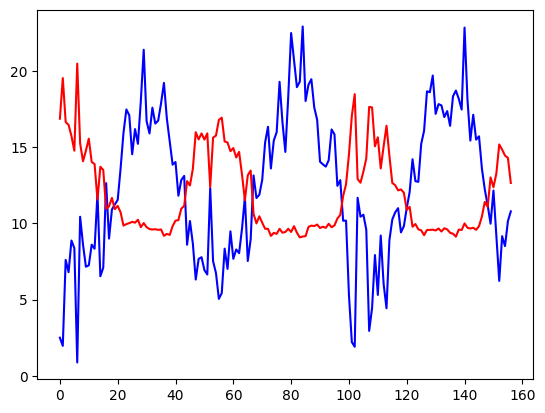

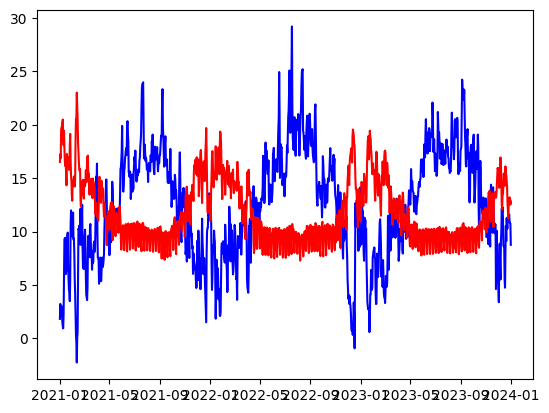

,year,weekNb,Date,Consommation,TN,TX,TM,TNSOL,TN50,DG,FF2M,DRR
0,2020,53,2021-01-02,16.872500,-0.054229,5.850249,2.498485,-3.174603,-2.239394,197.398589,0.900000,218.193122
1,2021,1,2021-01-07,19.542271,-0.758849,5.685075,1.961768,-4.095238,-3.242857,294.816540,0.907143,78.646429
2,2021,2,2021-01-14,16.653529,5.176972,10.144776,7.603886,2.659184,3.528571,16.160242,1.950000,209.721429
3,2021,3,2021-01-21,16.467814,4.416844,9.782729,6.801732,2.051701,2.818182,20.534926,2.335714,330.638095
4,2021,4,2021-01-28,15.735000,6.627292,11.105117,8.876407,4.896599,5.566234,30.813966,2.603571,439.926984
...,...,...,...,...,...,...,...,...,...,...,...,...
152,2023,48,2023-11-30,15.182914,3.429314,9.611874,6.225788,0.674026,1.918182,38.415261,1.389286,256.347619
153,2023,49,2023-12-07,14.846071,6.459740,12.174397,9.163265,4.413636,5.344156,12.507009,2.653571,319.619048
154,2023,50,2023-12-14,14.451571,6.219109,11.331911,8.509833,3.570779,4.905195,27.661594,1.514286,93.128571
155,2023,51,2023-12-21,14.302671,8.228386,11.963265,10.150835,6.836364,7.820779,0.000000,2.646429,153.395238


In [ ]:
#* Test lissage par semaine

combineData["weekNb"] = combineData["Date"].dt.isocalendar().week
combineData["year"] = combineData["Date"].dt.isocalendar().year

weekCombineData = combineData.groupby(["year",'weekNb']).mean().reset_index().sort_values(['year','weekNb'])
plt.plot(weekCombineData.index,weekCombineData["TM"],color="blue")
plt.plot(weekCombineData.index,weekCombineData["Consommation"],color="red")
plt.show()

plt.plot(combineData['Date'],combineData["TM"],color="blue")
plt.plot(combineData['Date'],combineData["Consommation"],color="red")
plt.show()
weekCombineData

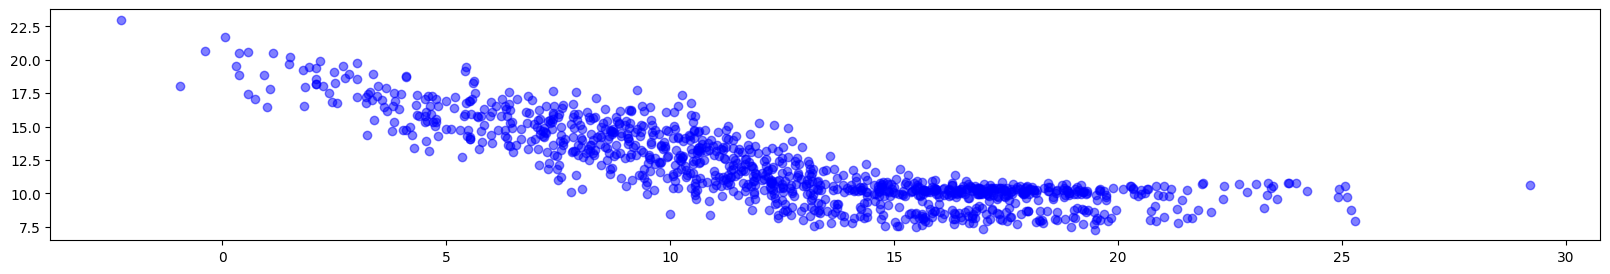

In [35]:
plt.scatter(combineData['TM'],combineData["Consommation"],color="blue",alpha=0.5)
plt.show()

**Test en ajoutant les consommations des derniers jours**

In [50]:
combinedShifted = combineData["Consommation"].shift([1,2,3,4,5])
combinedShifted = combineData.merge(combinedShifted,left_index=True,right_index=True)
combinedShifted = combinedShifted.dropna()
combinedShifted

,Date,Consommation,TN,TX,TM,TNSOL,TN50,DG,FF2M,DRR,Consommation_1,Consommation_2,Consommation_3,Consommation_4,Consommation_5
5,2021-01-06,19.8960,-0.023881,5.725373,2.182812,-3.285714,-2.290909,206.203704,0.500,16.200000,19.7384,19.5148,16.8716,17.2333,16.5126
6,2021-01-07,20.2171,-1.185075,6.294030,1.509091,-4.728571,-4.190909,428.576923,0.350,0.000000,19.8960,19.7384,19.5148,16.8716,17.2333
7,2021-01-08,20.4806,-1.686567,5.594030,1.142424,-5.280952,-4.763636,490.763636,0.525,88.000000,20.2171,19.8960,19.7384,19.5148,16.8716
8,2021-01-09,18.8735,-2.879104,5.235821,0.933333,-6.785714,-5.727273,500.283019,1.375,0.000000,20.4806,20.2171,19.8960,19.7384,19.5148
9,2021-01-10,18.0755,-0.917910,6.388060,2.250000,-4.980952,-3.863636,343.436364,0.925,0.000000,18.8735,20.4806,20.2171,19.8960,19.7384
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1090,2023-12-27,13.0967,10.071429,13.106494,11.606494,9.054545,9.736364,0.000000,3.925,159.222222,12.5922,11.2082,11.8459,12.6796,14.1239
1091,2023-12-28,13.1999,9.635065,12.889610,11.029870,7.940909,9.181818,0.000000,3.375,65.300000,13.0967,12.5922,11.2082,11.8459,12.6796
1092,2023-12-29,13.1522,9.820779,13.058442,10.805195,8.050000,9.127273,0.000000,2.700,105.111111,13.1999,13.0967,12.5922,11.2082,11.8459
1093,2023-12-30,12.5215,8.124675,12.955844,10.751948,5.809091,6.909091,0.000000,3.375,393.625000,13.1522,13.1999,13.0967,12.5922,11.2082


[]

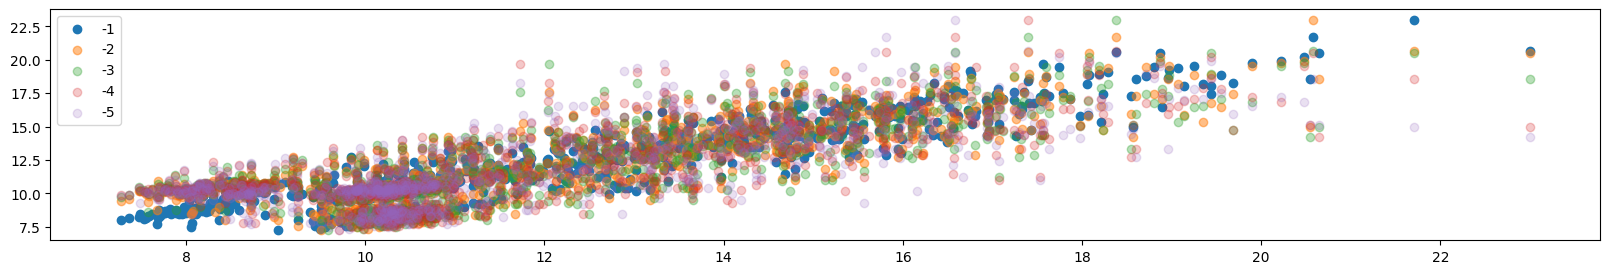

In [ ]:

#* Correlation entre la consommation et celle des jours antérieurs
for d in [1,2,3,4,5]:
    plt.scatter(combinedShifted["Consommation"],combinedShifted[f'Consommation_{d}'],label=f"-{d}",alpha=1/d)
plt.legend()
plt.plot()

score :  0.9055493194802352


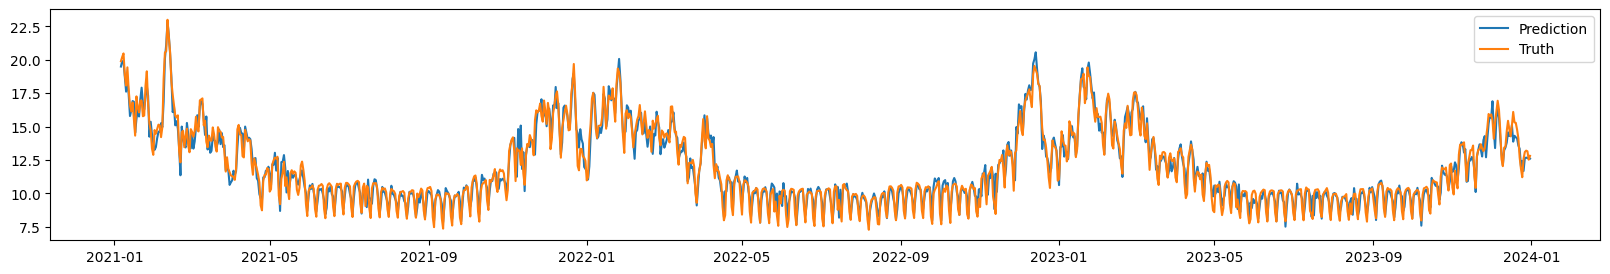

In [60]:
degree = 2
poly = PolynomialFeatures(degree)

linReg = LinearRegression()

linRegPipe = Pipeline([('poly',poly),("linReg",linReg)])
# features = combineData.drop(["Date","Consommation"],axis=1).to_numpy()
features = combinedShifted.drop(["Date","Consommation"],axis=1).to_numpy()
# features = combineData[['TM']].to_numpy()
y = combinedShifted[["Consommation"]].to_numpy()

# X = poly.fit_transform(features)
Xtrain,Xtest, yTrain, yTest = train_test_split(features,y,test_size=0.2)

linRegPipe.fit(Xtrain,yTrain)

# XtrainPoly = poly.fit_transform(Xtrain)
# XtestPoly = poly.fit_transform(Xtest)
# linRegScores = cross_val_score(linRegPipe,Xtrain,yTrain,cv=400)
# linRegPipe.fit(Xtrain,yTrain)
# linRegPipe.score(Xtest,yTest)
# linReg.fit(Xtrain,yTrain)
# linReg.score(Xtest,yTest)
# print(f"mean : {linRegScores.mean()}, var : {linRegScores.var()}")


# print(f'The regression coef {linReg.coef_}')
# print(f'The R^2 determination coef {linReg.score(Xtest,yTest)}')    
# print(f'The RSS {mean_squared_error(yTest,linReg.predict(Xtest))}')    

# linReg.score(XtrainPoly,yTrain)
# X.shape, y.shape
# regionAverage.tail(), energyData.tail()
# combineData
print("score : ",linRegPipe.score(Xtest,yTest))
plt.plot(combinedShifted["Date"],linRegPipe.predict(features),label="Prediction")
plt.plot(combinedShifted["Date"],y,label="Truth")
plt.legend()
plt.show()